# Formative 2: Data Merge and Feature Engineering

## 1. Load the data

We load the two spreadsheets. The social profiles file has the platform, engagement score, purchase interest score and review sentiment for each customer. The transactions file has the amount, date, product category and rating for each purchase.

In [1]:
# load the data

import pandas as pd

social = pd.read_excel("data/customer_social_profiles.xlsx")
trans = pd.read_excel("data/customer_transactions.xlsx")

print("Social profiles:", social.shape)
print(social.head())
print()
print("Transactions:", trans.shape)
print(trans.head())

Social profiles: (155, 5)
  customer_id_new social_media_platform  engagement_score  \
0            A178              LinkedIn                74   
1            A190               Twitter                82   
2            A150              Facebook                96   
3            A162               Twitter                89   
4            A197               Twitter                92   

   purchase_interest_score review_sentiment  
0                      4.9         Positive  
1                      4.8          Neutral  
2                      1.6         Positive  
3                      2.6         Positive  
4                      2.3          Neutral  

Transactions: (150, 6)
   customer_id_legacy  transaction_id  purchase_amount purchase_date  \
0                 151            1001              408    2024-01-01   
1                 192            1002              332    2024-01-02   
2                 114            1003              442    2024-01-03   
3                 1

## 2. Check Data Quality

Before merging, we check the data types, missing values and duplicates. Social profiles has 5 exact duplicate rows. Transactions has 10 missing ratings. Both tables repeat some customer IDs, because a customer can appear in several rows.

In [2]:
# check the data quality

print("=== SOCIAL PROFILES ===")
print(social.dtypes)
print("Missing values:")
print(social.isna().sum())
print("Duplicate rows:", social.duplicated().sum())
print("Duplicate customer IDs:", social["customer_id_new"].duplicated().sum())

print()
print("=== TRANSACTIONS ===")
print(trans.dtypes)
print("Missing values:")
print(trans.isna().sum())
print("Duplicate rows:", trans.duplicated().sum())
print("Duplicate customer IDs:", trans["customer_id_legacy"].duplicated().sum())

=== SOCIAL PROFILES ===
customer_id_new                str
social_media_platform          str
engagement_score             int64
purchase_interest_score    float64
review_sentiment               str
dtype: object
Missing values:
customer_id_new            0
social_media_platform      0
engagement_score           0
purchase_interest_score    0
review_sentiment           0
dtype: int64
Duplicate rows: 5
Duplicate customer IDs: 71

=== TRANSACTIONS ===
customer_id_legacy             int64
transaction_id                 int64
purchase_amount                int64
purchase_date         datetime64[us]
product_category                 str
customer_rating              float64
dtype: object
Missing values:
customer_id_legacy     0
transaction_id         0
purchase_amount        0
purchase_date          0
product_category       0
customer_rating       10
dtype: int64
Duplicate rows: 0
Duplicate customer IDs: 75


## 3. Remove Duplicate Rows (Social Profiles)

We remove the 5 exact duplicate rows so that no record is counted twice. Social profiles goes from 155 rows to 150.

In [3]:
# remove the duplicate rows in the social profile

print("Before:", social.shape)

social = social.drop_duplicates().reset_index(drop=True)

print("After:", social.shape)
print("Duplicate rows now:", social.duplicated().sum())

Before: (155, 5)
After: (150, 5)
Duplicate rows now: 0


## 4. Fill Missing Customer Ratings (Transactions)

We fill the 10 missing ratings with the median rating, 3.0. The median is a typical value that is not pulled up or down by a few very high or very low ratings.

In [4]:
# handle the missing values in customer_rating values

print("Missing ratings before:", trans["customer_rating"].isna().sum())

median_rating = trans["customer_rating"].median()
print("Median rating used:", median_rating)

trans["customer_rating"] = trans["customer_rating"].fillna(median_rating)

print("Missing ratings after:", trans["customer_rating"].isna().sum())

Missing ratings before: 10
Median rating used: 3.0
Missing ratings after: 0


## 5. Check How the Customer IDs Match

The social profiles use IDs like A178, while the transactions use numbers like 178. All 150 social IDs start with the letter A, and both tables use numbers between 100 and 199. 61 customer IDs appear in both tables. We assume the number inside the social ID is the same customer as the matching transaction ID. Neither file has a name or email to confirm this, so it is the only possible link.

In [5]:
# figure out how the two ID columns match

# 1. Do all social IDs follow the pattern letter + numbers?
print("IDs starting with 'A':", social["customer_id_new"].str.startswith("A").sum(), "out of", len(social))

# 2. Strip the 'A' and turn the rest into a number (stored in a temporary variable)
social_numbers = social["customer_id_new"].str[1:].astype(int)

print("Social ID range:", social_numbers.min(), "to", social_numbers.max())
print("Transaction ID range:", trans["customer_id_legacy"].min(), "to", trans["customer_id_legacy"].max())

# 3. How many IDs appear in both tables?
common = set(social_numbers) & set(trans["customer_id_legacy"])
print("IDs found in both tables:", len(common))
print("Unique IDs in social:", social_numbers.nunique())
print("Unique IDs in transactions:", trans["customer_id_legacy"].nunique())


IDs starting with 'A': 150 out of 150
Social ID range: 100 to 199
Transaction ID range: 100 to 199
IDs found in both tables: 61
Unique IDs in social: 84
Unique IDs in transactions: 75


## 6. Create a Shared Customer ID

We remove the letter A from the social IDs and turn the rest into a number. We copy the transaction IDs into a column with the same name. Both tables now have a customer_id column of the same type, which we use to join them.

In [6]:
# Create a shared ID column in both tables

# social: remove the leading 'A' and convert the rest to a number
social["customer_id"] = social["customer_id_new"].str[1:].astype(int)

# transactions: the legacy ID is already a number, so just copy it
trans["customer_id"] = trans["customer_id_legacy"]

print(social[["customer_id_new", "customer_id"]].head())
print()
print(trans[["customer_id_legacy", "customer_id"]].head())
print()
print("Same data type in both:", social["customer_id"].dtype == trans["customer_id"].dtype)

  customer_id_new  customer_id
0            A178          178
1            A190          190
2            A150          150
3            A162          162
4            A197          197

   customer_id_legacy  customer_id
0                 151          151
1                 192          192
2                 114          114
3                 171          171
4                 160          160

Same data type in both: True


## 7. Reduce Social Profiles to One Row per Customer

The 150 social rows belong to only 84 customers, so some customers have several rows. Joining them directly would multiply the purchase rows. We reduce them to one row per customer: the two scores are averaged, and the platform and sentiment take the customer's most common value.

In [7]:
# Reduce social profiles to one row per customer 

social_customer = social.groupby("customer_id").agg(
    engagement_score=("engagement_score", "mean"),
    purchase_interest_score=("purchase_interest_score", "mean"),
    social_media_platform=("social_media_platform", lambda x: x.mode().iloc[0]),
    review_sentiment=("review_sentiment", lambda x: x.mode().iloc[0]),
).reset_index()

print(social_customer.shape)
print(social_customer.head())
print("Duplicate customer IDs:", social_customer["customer_id"].duplicated().sum())

(84, 5)
   customer_id  engagement_score  purchase_interest_score  \
0          100         77.000000                 4.400000   
1          101         68.000000                 1.000000   
2          102         51.000000                 4.800000   
3          103         64.333333                 2.866667   
4          104         83.000000                 2.933333   

  social_media_platform review_sentiment  
0             Instagram         Negative  
1               Twitter          Neutral  
2              LinkedIn          Neutral  
3             Instagram         Positive  
4               Twitter         Negative  
Duplicate customer IDs: 0


## 8. Merge the Two Tables

We use a left join with the transactions on the left, which keeps all 150 purchases. Each purchase gets its customer's social data. 117 purchases have social data and 33 do not, because those customers have no social profile. The merge is set to stop with an error if any rows were multiplied.

In [8]:
# Merge the 2 tables

merged = trans.merge(social_customer, on="customer_id", how="left", validate="many_to_one")

print("Merged shape:", merged.shape)
print("Rows with social data:", merged["engagement_score"].notna().sum())
print("Rows without social data:", merged["engagement_score"].isna().sum())
print()
print(merged.head())

Merged shape: (150, 11)
Rows with social data: 117
Rows without social data: 33

   customer_id_legacy  transaction_id  purchase_amount purchase_date  \
0                 151            1001              408    2024-01-01   
1                 192            1002              332    2024-01-02   
2                 114            1003              442    2024-01-03   
3                 171            1004              256    2024-01-04   
4                 160            1005               64    2024-01-05   

  product_category  customer_rating  customer_id  engagement_score  \
0           Sports              2.3          151         71.666667   
1      Electronics              4.2          192         60.000000   
2      Electronics              2.1          114         87.000000   
3         Clothing              2.8          171               NaN   
4         Clothing              1.3          160         72.666667   

   purchase_interest_score social_media_platform review_sentiment

## 9. Fill Missing Social Data

33 purchases belong to customers with no social profile. We keep them, because dropping them would remove 22% of the data. The two scores are filled with the median, and the platform and sentiment are labeled "Unknown". We first add a has_social_profile column (1 = yes, 0 = no), so the model can tell real values from filled ones.

In [9]:
# Fill in the missing social data for those 33 rows

# add a column to show which customers have a social profile (1 = yes, 0 = no)
merged["has_social_profile"] = merged["engagement_score"].notna().astype(int)

# fill numbers with the median
for col in ["engagement_score", "purchase_interest_score"]:
    merged[col] = merged[col].fillna(merged[col].median())

# fill text columns with "Unknown"
for col in ["social_media_platform", "review_sentiment"]:
    merged[col] = merged[col].fillna("Unknown")

print("Missing values left:")
print(merged.isna().sum())
print()
print(merged["has_social_profile"].value_counts())

Missing values left:
customer_id_legacy         0
transaction_id             0
purchase_amount            0
purchase_date              0
product_category           0
customer_rating            0
customer_id                0
engagement_score           0
purchase_interest_score    0
social_media_platform      0
review_sentiment           0
has_social_profile         0
dtype: int64

has_social_profile
1    117
0     33
Name: count, dtype: int64


## 10. Check if the Merge Is Correct

We check that the merged table still has 150 rows, that no transaction ID is repeated, and that the values are right for one customer. Customer 103 has three social rows with engagement scores 77, 58 and 58. The merged table shows their average, 64.33, on each of their purchases, so the merge worked as intended.

In [10]:
# Check that the merge is correct (post-merge checks)

# 1. same number of rows as the original transactions?
print("Rows match original transactions:", len(merged) == len(trans))

# 2. every transaction appears exactly once?
print("Duplicate transaction IDs:", merged["transaction_id"].duplicated().sum())

# 3. spot check: customer 103 in the original social table vs the merged table
print()
print("Original social rows for customer 103:")
print(social[social["customer_id"] == 103][["engagement_score", "purchase_interest_score"]])
print()
print("Merged rows for customer 103:")
print(merged[merged["customer_id"] == 103][["transaction_id", "engagement_score", "purchase_interest_score"]])

Rows match original transactions: True
Duplicate transaction IDs: 0

Original social rows for customer 103:
    engagement_score  purchase_interest_score
15                77                      2.3
38                58                      3.6
39                58                      2.7

Merged rows for customer 103:
    transaction_id  engagement_score  purchase_interest_score
51            1052         64.333333                 2.866667
71            1072         64.333333                 2.866667
75            1076         64.333333                 2.866667


## 11. Summary Statistics

The data has no impossible values. Purchase amounts range from 51 to 495, ratings from 1 to 5, and engagement scores from 50 to 99. The five product categories are fairly balanced (Sports 35, Electronics 34, Clothing 28, Groceries 28, Books 25), so random guessing would be right about 20% of the time.

In [11]:
# EDA with statistical summary

print("Variable types:")
print(merged.dtypes)
print()
print("Summary of number columns:")
print(merged[["purchase_amount", "customer_rating", "engagement_score", "purchase_interest_score"]].describe())
print()
print("Product categories (what we want to predict):")
print(merged["product_category"].value_counts())

Variable types:
customer_id_legacy                  int64
transaction_id                      int64
purchase_amount                     int64
purchase_date              datetime64[us]
product_category                      str
customer_rating                   float64
customer_id                         int64
engagement_score                  float64
purchase_interest_score           float64
social_media_platform                 str
review_sentiment                      str
has_social_profile                  int64
dtype: object

Summary of number columns:
       purchase_amount  customer_rating  engagement_score  \
count       150.000000       150.000000        150.000000   
mean        280.780000         2.986000         74.780556   
std         121.329595         1.165789         11.245823   
min          51.000000         1.000000         50.000000   
25%         179.000000         2.100000         68.312500   
50%         274.000000         3.000000         77.000000   
75%        

## 12. Plot 1: Purchase Amount Distribution

Purchase amounts are spread fairly evenly between about 50 and 500. No price range dominates, and there are no extreme values.

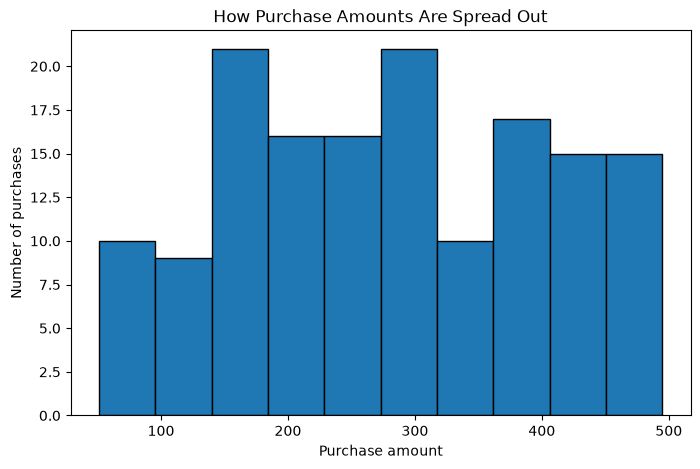

In [12]:
# Draw a bar chart (a histogram) that shows how many purchases fall into each price range

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(merged["purchase_amount"], bins=10, edgecolor="black")
plt.title("How Purchase Amounts Are Spread Out")
plt.xlabel("Purchase amount")
plt.ylabel("Number of purchases")
plt.show()

## 13. Plot 2: Looking for Unusual Values

Customer ratings and engagement scores have no unusual values. A few customers have very low purchase interest scores (about 1.0 to 1.4). These are valid scores on the 1 to 5 scale and not errors, so we keep them.

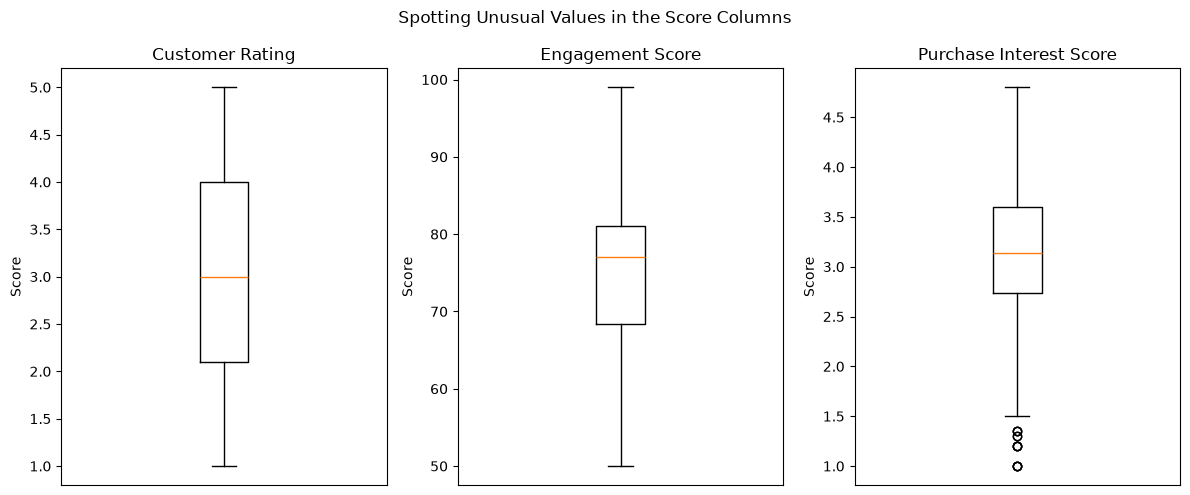

In [13]:
# Draws another box plot for each of the three score columns to look for unusual values

fig, axes = plt.subplots(1, 3, figsize=(12, 5))

columns = ["customer_rating", "engagement_score", "purchase_interest_score"]
titles = ["Customer Rating", "Engagement Score", "Purchase Interest Score"]

for ax, col, title in zip(axes, columns, titles):
    ax.boxplot(merged[col])
    ax.set_title(title)
    ax.set_ylabel("Score")
    ax.set_xticks([])

plt.suptitle("Spotting Unusual Values in the Score Columns")
plt.tight_layout()
plt.show()

## 14. Plot 3: Relationships Between Number Columns

All the relationships between the number columns are weak (every value is below 0.2). The strongest are engagement score with purchase interest (0.19) and customer rating with purchase interest (0.16). No column duplicates another, but no single column predicts another either, so predicting the product is expected to be hard.

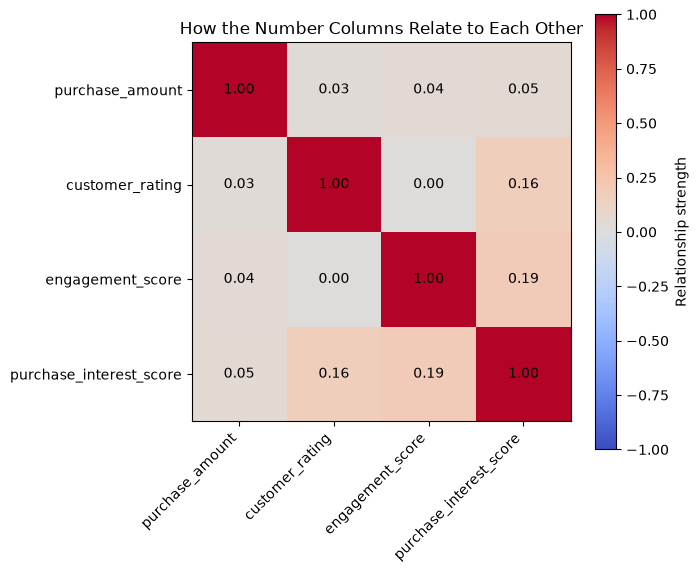

In [14]:
# Draw a 3rd plot (colored grid) to determine which columns move together

cols = ["purchase_amount", "customer_rating", "engagement_score", "purchase_interest_score"]
corr = merged[cols].corr()

plt.figure(figsize=(7, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Relationship strength")
plt.xticks(range(len(cols)), cols, rotation=45, ha="right")
plt.yticks(range(len(cols)), cols)

for i in range(len(cols)):
    for j in range(len(cols)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")

plt.title("How the Number Columns Relate to Each Other")
plt.tight_layout()
plt.show()

## 15. Create Date Features

We turn the purchase date into the month, the day of the week and a weekend flag, because a model cannot use a raw date. The data covers January to May 2024 with one purchase per day, so these features may not add much.

In [15]:
# Create new columns from the purchase date

merged["purchase_month"] = merged["purchase_date"].dt.month
merged["purchase_day_of_week"] = merged["purchase_date"].dt.dayofweek   # 0 = Monday, 6 = Sunday
merged["is_weekend"] = (merged["purchase_day_of_week"] >= 5).astype(int)

print(merged[["purchase_date", "purchase_month", "purchase_day_of_week", "is_weekend"]].head(10))
print()
print(merged["purchase_month"].value_counts().sort_index())

  purchase_date  purchase_month  purchase_day_of_week  is_weekend
0    2024-01-01               1                     0           0
1    2024-01-02               1                     1           0
2    2024-01-03               1                     2           0
3    2024-01-04               1                     3           0
4    2024-01-05               1                     4           0
5    2024-01-06               1                     5           1
6    2024-01-07               1                     6           1
7    2024-01-08               1                     0           0
8    2024-01-09               1                     1           0
9    2024-01-10               1                     2           0

purchase_month
1    31
2    29
3    31
4    30
5    29
Name: count, dtype: int64


C:\Users\HP\AppData\Local\Temp\ipykernel_3448\3800515992.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  merged["purchase_day_of_week"] = merged["purchase_date"].dt.dayofweek   # 0 = Monday, 6 = Sunday


## 16. Turn Text Columns into Numbers

We convert the platform and sentiment columns into separate 0/1 columns (one-hot encoding), including an "Unknown" column for customers without a social profile. This gives the model numbers instead of text.

In [16]:
# Turn the text columns into numbers

dummies = pd.get_dummies(merged[["social_media_platform", "review_sentiment"]], dtype=int)

# remove old copies first, so running this cell twice doesn't duplicate columns
merged = merged.drop(columns=[c for c in dummies.columns if c in merged.columns])
merged = pd.concat([merged, dummies], axis=1)

print("New columns added:")
print(list(dummies.columns))
print()
print("Merged shape now:", merged.shape)
print(dummies.head())

New columns added:
['social_media_platform_Facebook', 'social_media_platform_Instagram', 'social_media_platform_LinkedIn', 'social_media_platform_TikTok', 'social_media_platform_Twitter', 'social_media_platform_Unknown', 'review_sentiment_Negative', 'review_sentiment_Neutral', 'review_sentiment_Positive', 'review_sentiment_Unknown']

Merged shape now: (150, 25)
   social_media_platform_Facebook  social_media_platform_Instagram  \
0                               0                                0   
1                               0                                1   
2                               1                                0   
3                               0                                0   
4                               0                                1   

   social_media_platform_LinkedIn  social_media_platform_TikTok  \
0                               0                             0   
1                               0                             0   
2             

## 17. Save the Merged Dataset

We save the merged table with all engineered features to data/merged_dataset.csv. It has 150 rows and 25 columns, and we reload it to confirm that it saved correctly.

In [17]:
# Save the merged dataset 

merged.to_csv("data/merged_dataset.csv", index=False)

check = pd.read_csv("data/merged_dataset.csv")
print("Saved and reloaded shape:", check.shape)
print(list(check.columns))

Saved and reloaded shape: (150, 25)
['customer_id_legacy', 'transaction_id', 'purchase_amount', 'purchase_date', 'product_category', 'customer_rating', 'customer_id', 'engagement_score', 'purchase_interest_score', 'social_media_platform', 'review_sentiment', 'has_social_profile', 'purchase_month', 'purchase_day_of_week', 'is_weekend', 'social_media_platform_Facebook', 'social_media_platform_Instagram', 'social_media_platform_LinkedIn', 'social_media_platform_TikTok', 'social_media_platform_Twitter', 'social_media_platform_Unknown', 'review_sentiment_Negative', 'review_sentiment_Neutral', 'review_sentiment_Positive', 'review_sentiment_Unknown']


## 18. Prepare the Data for the Model

We split the data into the inputs (18 columns) and the answer, the product category. The ID columns, the raw date and the original text columns are left out because they give the model no useful clue. We use 80% of the rows (120) for training and keep 20% (30) as a test set the model has never seen. The split keeps the product mix the same in both parts.

In [18]:
from sklearn.model_selection import train_test_split

# the answer we want the model to predict
y = merged["product_category"]

# the columns the model is allowed to look at
drop_cols = ["customer_id_legacy", "transaction_id", "customer_id", "purchase_date",
             "product_category", "social_media_platform", "review_sentiment"]
X = merged.drop(columns=drop_cols)

# 80% to learn from, 20% to test on (stratify keeps the product mix equal in both)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Input columns used:", X.shape[1])
print(list(X.columns))
print()
print("Training rows:", X_train.shape[0])
print("Test rows:", X_test.shape[0])
print()
print("Products in the test set:")
print(y_test.value_counts())

Input columns used: 18
['purchase_amount', 'customer_rating', 'engagement_score', 'purchase_interest_score', 'has_social_profile', 'purchase_month', 'purchase_day_of_week', 'is_weekend', 'social_media_platform_Facebook', 'social_media_platform_Instagram', 'social_media_platform_LinkedIn', 'social_media_platform_TikTok', 'social_media_platform_Twitter', 'social_media_platform_Unknown', 'review_sentiment_Negative', 'review_sentiment_Neutral', 'review_sentiment_Positive', 'review_sentiment_Unknown']

Training rows: 120
Test rows: 30

Products in the test set:
product_category
Sports         7
Electronics    7
Clothing       6
Groceries      5
Books          5
Name: count, dtype: int64


## 19. Train and Evaluate the Product Recommendation Model

We first train a Random Forest with no limits. It scores 1.0 on the training rows but only 0.167 on the test rows, with a loss of 1.908. This is overfitting: the model memorized the training rows instead of learning patterns that carry over to new data.

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

test_pred = model.predict(X_test)
test_proba = model.predict_proba(X_test)

print("Accuracy on training rows:", round(accuracy_score(y_train, model.predict(X_train)), 3))
print("Accuracy on test rows:   ", round(accuracy_score(y_test, test_pred), 3))
print("F1-score on test rows:   ", round(f1_score(y_test, test_pred, average="weighted"), 3))
print("Loss on test rows:       ", round(log_loss(y_test, test_proba, labels=model.classes_), 3))

Accuracy on training rows: 1.0
Accuracy on test rows:    0.167
F1-score on test rows:    0.152
Loss on test rows:        1.908


## 20. Compare Simpler Models with Cross-Validation

With only 30 test rows, a single split is unreliable. We use 5-fold cross-validation on all 150 rows to compare three models. The average accuracies are 0.247 for the original Random Forest, 0.247 for a shallow Random Forest and 0.227 for Logistic Regression. All are close to random guessing (0.20), and the differences between them are within normal variation.

In [20]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Random Forest (original)": RandomForestClassifier(n_estimators=100, random_state=42),
    "Random Forest (shallow)": RandomForestClassifier(n_estimators=100, max_depth=3, min_samples_leaf=5, random_state=42),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, m in models.items():
    scores = cross_val_score(m, X, y, cv=cv, scoring="accuracy")
    print(f"{name}: average accuracy {scores.mean():.3f}  (the 5 scores: {scores.round(2)})")

print()
print("Random guessing would score about 0.20")

Random Forest (original): average accuracy 0.247  (the 5 scores: [0.17 0.27 0.23 0.23 0.33])
Random Forest (shallow): average accuracy 0.247  (the 5 scores: [0.2  0.23 0.2  0.3  0.3 ])
Logistic Regression: average accuracy 0.227  (the 5 scores: [0.1  0.27 0.27 0.27 0.23])

Random guessing would score about 0.20


## 21. Train and Evaluate the Final Product Model

We choose the shallow Random Forest because it scores the same as the others but memorizes less. Its training accuracy drops to 0.633. On the test rows it gets an accuracy of 0.2, an F1-score of 0.174 and a loss of 1.675. This is close to random guessing (accuracy 0.20, loss about 1.61). We explain it by the small dataset (150 rows) and the weak relationships between the features and the product category.

In [21]:
final_model = RandomForestClassifier(n_estimators=100, max_depth=3, min_samples_leaf=5, random_state=42)
final_model.fit(X_train, y_train)

test_pred = final_model.predict(X_test)
test_proba = final_model.predict_proba(X_test)

print("Accuracy on training rows:", round(accuracy_score(y_train, final_model.predict(X_train)), 3))
print("Accuracy on test rows:   ", round(accuracy_score(y_test, test_pred), 3))
print("F1-score on test rows:   ", round(f1_score(y_test, test_pred, average="weighted"), 3))
print("Loss on test rows:       ", round(log_loss(y_test, test_proba, labels=final_model.classes_), 3))

Accuracy on training rows: 0.633
Accuracy on test rows:    0.2
F1-score on test rows:    0.174
Loss on test rows:        1.675


## 22. Save the Product Model

We save the final model and its list of input columns to the models folder, so the command-line app can load them without retraining. We load the model back and make one prediction to check the file works.

In [22]:
import os
import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(final_model, "models/product_model.pkl")
joblib.dump(list(X.columns), "models/product_model_columns.pkl")

# check: load it back and make one test prediction
loaded = joblib.load("models/product_model.pkl")
print("Model loaded back OK. Classes it can predict:", list(loaded.classes_))
print("Prediction for the first test row:", loaded.predict(X_test.iloc[[0]])[0])

Model loaded back OK. Classes it can predict: ['Books', 'Clothing', 'Electronics', 'Groceries', 'Sports']
Prediction for the first test row: Clothing
